# 01 — World and energy

Build a seeded map (hills, no-fly circles, wind, base, targets) and price a single move.
Energy is `a·d + b·climb + c·d·headwind + e·payload·d`, never cheaper than `0.3·d`.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from uavplanner.config import Config
from uavplanner.energy import e_min, move_energy
from uavplanner.models import EnergyCoef
from uavplanner.viz import plot_world
from uavplanner.world import make_targets, make_world

cfg = Config(seed=42)
rng = np.random.default_rng(cfg.seed)
world = make_world(cfg, rng)
targets = make_targets(world, cfg, rng)
print("base", world.base, "wind", tuple(round(x, 2) for x in world.wind))
print("targets", len(targets), "terrain max m", round(float(world.terrain.max()), 1))
print("check values", move_energy(EnergyCoef(), 1, 20, 4, 1), move_energy(EnergyCoef(), 1, -20, -4, 1), e_min(EnergyCoef(), 8))

base (39, 48) wind (5.18, -3.03)
targets 6 terrain max m 300.0
check values 2.4699999999999998 0.83 0.36


saved /media/abdullahmughal/b74a1ef7-556e-41b4-9ad8-72e96d04151d/Energy_Aware_UAV_Mission_Planner/results/fig_world.png


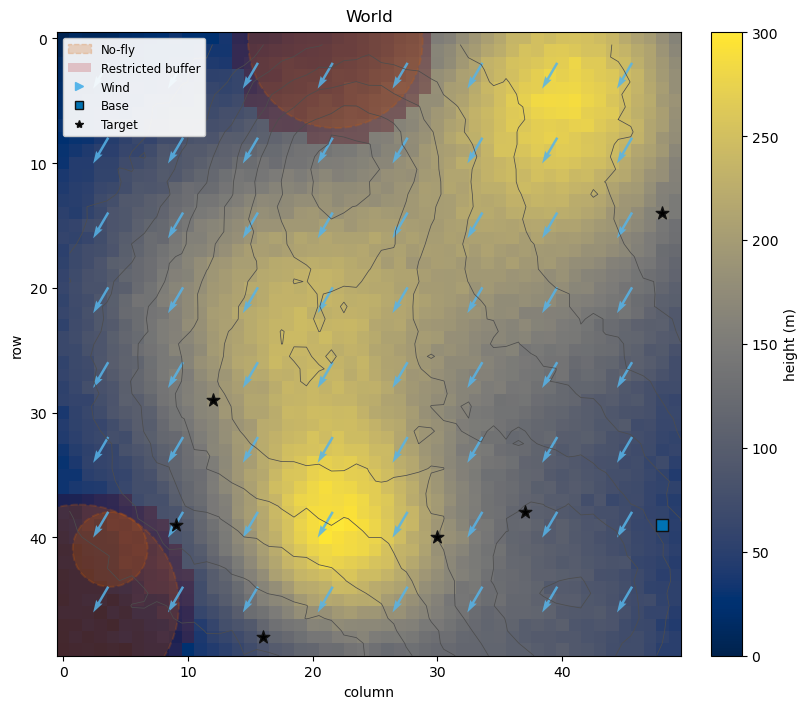

In [2]:
fig, ax = plt.subplots(figsize=(8.4, 7.2))
plot_world(ax, world, targets)
fig.tight_layout()
out = ROOT / "results" / "fig_world.png"
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=130, bbox_inches="tight")
print("saved", out)
